# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [2]:
ПІБ = 'Лящук Соломія'       
ГРУПА = 'ШІ-33'     
ВАРІАНТ = 6    

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [3]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Лящук Соломія, ШІ-33, варіант 6
ваш потік:                   P>30
ваша пара для графіка 3:     густина вітру та потік P>1
ваш агрегат для етапу 4:     мінімум
ваше додаткове питання:      У яку добу середнє значення вашого потоку було найбільшим? А найменшим?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [5]:

df = pd.read_excel(ФАЙЛ)
print(df.head())
print(df.dtypes)

   Unnamed: 0        ftp://ftp.swpc.noaa.gov/pub/lists/particle/ Unnamed: 2 Unnamed: 3 Unnamed: 4 Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9 Unnamed: 10 Unnamed: 11 Unnamed: 12  \
0         NaN                                                NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
1         NaN                :Data_list: 20170901_Gs_part_5m.txt        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
2         NaN                     :Created: 2017 Sep 02 0011 UTC        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
3         NaN  # Prepared by the U.S. Dept. of Commerce, NOAA...        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN         NaN         NaN         NaN   
4         NaN  # Please send comments an

**Відповідь 1.1:** *(чому звичайне читання дало саме такий результат)*

Pandas взяв за заголовок таблиці перший рядок аркуша — а це не назви стовпців, а службовий текст, через це стовпці отримали імена Unnamed: N, а дані у перших рядках виявились текстовими коментарями, тому типи стовпців вийшли object замість очікуваних float64/int64.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [6]:

RAW = pd.read_excel(ФАЙЛ, header=None)
print(RAW.shape)
RAW.head(30)

(7226, 32)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [7]:

filled = RAW.notna().sum()
print(filled)

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64


**Відповідь 1.3:** *(скільки таблиць і які стовпці кожна займає)*

У аркуші 3 таблиці, розділені порожніми стовпцями-розділювачами (стовпці 0, 15, 20–23 мають 0 заповнених клітинок): таблиця A займає стовпці 1–14, таблиця B — стовпці 16–19, таблиця C — стовпці 24–31.

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [8]:
for col in range(RAW.shape[1]):
    text = RAW.iloc[0:22, col].dropna()
    if not text.empty:
        print(f"--- column {col} ---")
        print(text.to_string())
        print()


--- column 1 ---
0           ftp://ftp.swpc.noaa.gov/pub/lists/particle/
2                   :Data_list: 20170901_Gs_part_5m.txt
3                        :Created: 2017 Sep 02 0011 UTC
4     # Prepared by the U.S. Dept. of Commerce, NOAA...
5     # Please send comments and suggestions to SWPC...
6                                                    # 
7                  # Label: P > 1 = Particles at >1 Mev
8                  # Label: P > 5 = Particles at >5 Mev
9                 # Label: P >10 = Particles at >10 Mev
10                # Label: P >30 = Particles at >30 Mev
11                # Label: P >50 = Particles at >50 Mev
12               # Label: P>100 = Particles at >100 Mev
13               # Label: E>0.8 = Electrons at >0.8 Mev
14               # Label: E>2.0 = Electrons at >2.0 Mev
15               # Label: E>4.0 = Electrons at >4.0 Mev
16                # Units: Particles = Protons/cm2-s-sr
17              # Units: Electrons = Electrons/cm2-s-sr
18                             

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | GOES-15 | Protons/cm2-s-sr |
| B | Daily Solar Data (quar_DSD.txt) | sfu (solar flux units) |
| C | SOHO CELIAS Proton Monitor | Proton speed [km/sec] and Proton density [protons per cubic centimeter] |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [9]:
A = RAW.iloc[26:26+7200, 1:15].copy()
A.columns = ['YR','MO','DA','HHMM','MJD','SOD','P>1','P>5','P>10','P>30','P>50','P>100','E>0.8','E>2.0']
A = A.apply(pd.to_numeric, errors='coerce')

B = RAW.iloc[27:27+25, 16:20].copy()
B.columns = ['YR','MO','DA','F10.7']
B = B.apply(pd.to_numeric, errors='coerce')

C = RAW.iloc[27:27+601, 24:32].copy()
C.columns = ['idx1','idx2','YR','MO','DA','HH','SPEED','DENSITY']
C = C.apply(pd.to_numeric, errors='coerce')
C = C.drop(columns=['idx1','idx2'])

print(A.shape, B.shape, C.shape)


(7200, 14) (25, 4) (601, 6)


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [10]:
A['ts'] = pd.to_datetime(dict(year=A['YR'], month=A['MO'], day=A['DA'],
                               hour=A['HHMM']//100, minute=A['HHMM']%100))
B['ts'] = pd.to_datetime(dict(year=B['YR'], month=B['MO'], day=B['DA']))
C['ts'] = pd.to_datetime(dict(year=C['YR']+2000, month=C['MO'], day=C['DA'], hour=C['HH']))

for name, t in [('A', A), ('B', B), ('C', C)]:
    print(name, t['ts'].min(), t['ts'].max())


A 2017-08-28 00:00:00 2017-09-21 23:55:00
B 2017-08-28 00:00:00 2017-09-21 00:00:00
C 2017-08-28 00:00:00 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [11]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [12]:
for name, t in [('A', A), ('B', B), ('C', C)]:
    print(f"=== Таблиця {name} ===")
    print("Розмір:", t.shape)
    print("\nТипи стовпців:\n", t.dtypes)
    print("\nПропуски по стовпцях:\n", t.isna().sum())
    print("\nПовних дублікатів рядків:", t.duplicated().sum())
    print("\nОписові статистики:\n", t.describe())
    print("\n" + "="*50 + "\n")


=== Таблиця A ===
Розмір: (7200, 15)

Типи стовпців:
 YR                int64
MO                int64
DA                int64
HHMM              int64
MJD               int64
SOD               int64
P>1             float64
P>5             float64
P>10            float64
P>30            float64
P>50            float64
P>100           float64
E>0.8           float64
E>2.0           float64
ts       datetime64[ns]
dtype: object

Пропуски по стовпцях:
 YR       0
MO       0
DA       0
HHMM     0
MJD      0
SOD      0
P>1      3
P>5      3
P>10     3
P>30     3
P>50     3
P>100    3
E>0.8    3
E>2.0    3
ts       0
dtype: int64

Повних дублікатів рядків: 0

Описові статистики:
            YR           MO           DA         HHMM           MJD           SOD           P>1          P>5         P>10         P>30         P>50       P>100          E>0.8          E>2.0  \
count  7200.0  7200.000000  7200.000000  7200.000000   7200.000000   7200.000000   7197.000000  7197.000000  7197.000000  7197.

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [13]:

cols = ['SPEED', 'DENSITY']

for c in cols:
    neg_mask = C[c] < 0
    print(f"{c}: від'ємних значень = {neg_mask.sum()}")

print("\nДо заміни:")
print(C[cols].agg(['mean', 'min']))

C[cols] = C[cols].where(C[cols] >= 0, np.nan)

print("\nПісля заміни:")
print(C[cols].agg(['mean', 'min']))


SPEED: від'ємних значень = 8
DENSITY: від'ємних значень = 8

До заміни:
           SPEED   DENSITY
mean  506.547421  2.907654
min    -1.000000 -1.000000

Після заміни:
           SPEED   DENSITY
mean  513.394604  2.960371
min   277.000000  0.100000


**Відповідь 3.2:** *(що це за значення, скільки їх, як вони спотворювали середнє)*

У стовпцях SPEED і DENSITY знайдено по 8 від'ємних значень, усі рівні -1 — це технічний код "дані відсутні". До заміни ці -1 занижували статистику: середнє SPEED було 506.55 (стало 513.39 після заміни на NaN), середнє DENSITY — 2.91 (стало 2.96). Мінімум змінився найпомітніше: з -1.00 до реалістичних 277.0 км/с (SPEED) і 0.10 (DENSITY).

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [ ]:

A[['YR','MO','DA','HHMM','MJD','SOD']].describe()

,YR,MO,DA,HHMM,MJD,SOD
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000


**Відповідь 3.3:** *(які це стовпці та чому середнє для них не має сенсу)*

Стовпці YR, MO, DA, HHMM, MJD, SOD — це компоненти часової мітки (рік, місяць, день, час, модифікований юліанський день, секунда доби), а не результат вимірювання. Середнє й стандартне відхилення для них не мають фізичного сенсу: наприклад, середній "номер місяця" 8.84 нічого не вимірює — це просто наслідок того, що в даних більше вересневих рядків, ніж серпневих. На відміну від них, для P>1, E>0.8 тощо середнє логічне — це реальні виміряні потоки частинок.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [ ]:
flux_cols = ['P>1','P>5','P>10','P>30','P>50','P>100','E>0.8','E>2.0']

A_hourly = A.set_index('ts')[flux_cols].resample('h').agg(['mean', 'max'])
A_hourly.columns = [f'{col}_{stat}' for col, stat in A_hourly.columns]
A_hourly = A_hourly.reset_index()

print(A_hourly.shape)
A_hourly.head()

(600, 17)


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

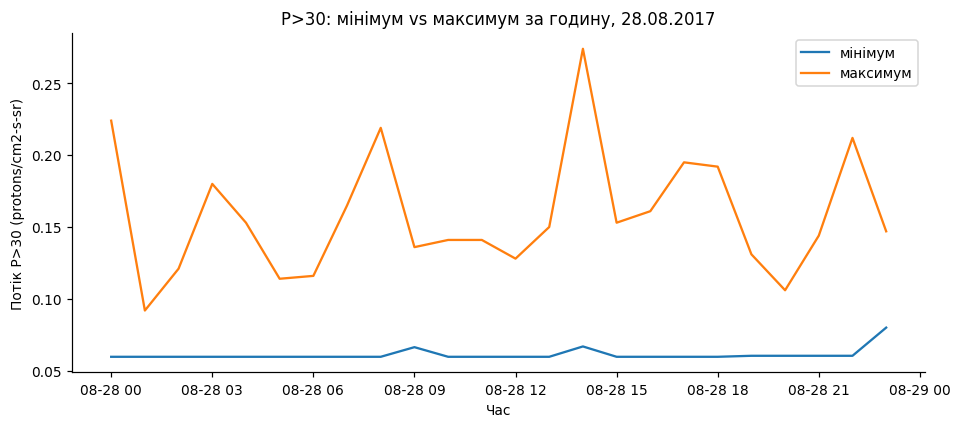

In [ ]:
day = pd.to_datetime('2017-08-28').date()
one_day = A[A['ts'].dt.date == day]

hourly_min = one_day.set_index('ts')['P>30'].resample('h').min()
hourly_max = one_day.set_index('ts')['P>30'].resample('h').max()

plt.figure(figsize=(10, 4))
plt.plot(hourly_min.index, hourly_min.values, label='мінімум')
plt.plot(hourly_max.index, hourly_max.values, label='максимум')
plt.xlabel('Час')
plt.ylabel('Потік P>30 (protons/cm2-s-sr)')
plt.title('P>30: мінімум vs максимум за годину, 28.08.2017')
plt.legend()
plt.show()

**Відповідь 4.2:** *(чим відрізняються криві та коли це важливо)*

Мінімум і максимум потоку P>30 за годину помітно розходяться: мінімум тримається біля стабільно низького фонового рівня, тоді як максимум реагує на короткі різкі сплески активності. Різниця стає суттєвою саме в години підвищеної сонячної активності — коли протягом години трапляється короткочасний викид частинок, максимум різко підскакує, а мінімум (і тим більше середнє) майже не змінюються, бо більшість 5-хвилинних вимірів у цій годині все одно лишаються низькими.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [ ]:
M = pd.merge(A_hourly, C, on='ts', how='inner')
print('inner:', M.shape)

M_outer = pd.merge(A_hourly, C, on='ts', how='outer')
print('outer:', M_outer.shape)

M = M_outer

M['date'] = M['ts'].dt.date
B['date'] = B['ts'].dt.date
M = pd.merge(M, B[['date', 'F10.7']], on='date', how='outer')
M = M.drop(columns=['date'])

print(M.shape)
M[M.isna().any(axis=1)]

inner: (600, 23)
outer: (601, 23)
(601, 24)


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max,YR,MO,DA,HH,SPEED,DENSITY,F10.7
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,17,9,4,7,NaN,NaN,140.0
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,17,9,4,8,NaN,NaN,140.0
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,17,9,4,9,NaN,NaN,140.0
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,17,9,4,10,NaN,NaN,140.0
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,17,9,4,11,NaN,NaN,140.0
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,17,9,4,12,NaN,NaN,140.0
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,17,9,4,13,NaN,NaN,140.0
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,17,9,4,14,NaN,NaN,140.0
600,2017-09-22 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17,9,22,0,381.0,1.0,NaN


**Відповідь 4.3:** *(який тип об'єднання обрано, скільки рядків дає кожен і чому)*

Обрано how='outer': inner дає 600 рядків, outer — 601, тобто в C є одна година (на краю періоду), якої немає в A_hourly. Обрано outer, щоб не втрачати жодного виміру мовчки, а бачити пропуски явно (як і показано в клітинці нижче — там кілька рядків з NaN, зокрема через технічний розрив у даних 4 вересня вранці й на межі періоду спостережень, де F10.7 з таблиці B не покриває останню годину).

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [ ]:
def classify(x):
    if pd.isna(x):
        return np.nan
    elif x < 10:
        return 'тиха'
    elif x < 1000:
        return 'активна'
    else:
        return 'дуже активна'

M['група'] = M['P>10_max'].apply(classify)
print(M['група'].value_counts())

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [32]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Середнє: 18.831272835858584
Медіана: 0.137825


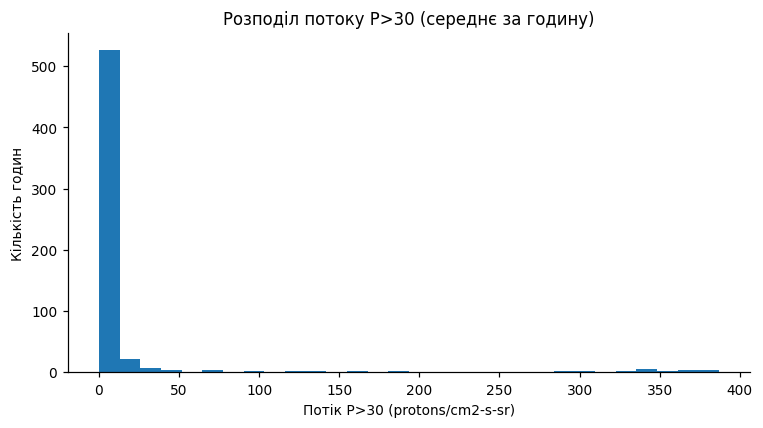

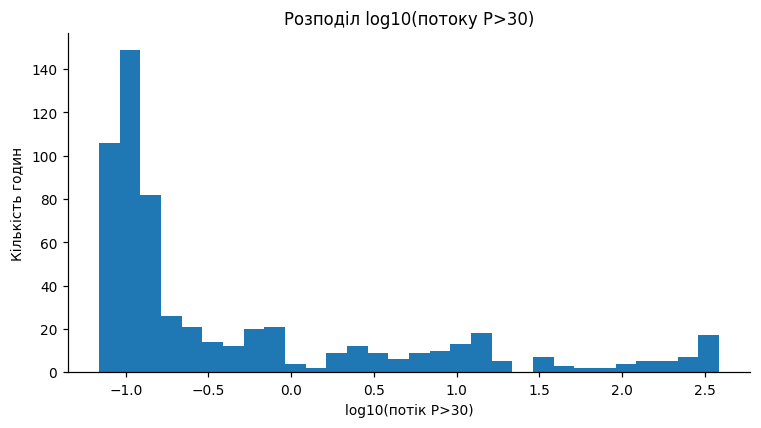

In [ ]:
data = M['P>30_mean'].dropna()
print('Середнє:', data.mean())
print('Медіана:', data.median())

plt.figure(figsize=(8, 4))
plt.hist(data, bins=30)
plt.xlabel('Потік P>30 (protons/cm2-s-sr)')
plt.ylabel('Кількість годин')
plt.title('Розподіл потоку P>30 (середнє за годину)')
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(np.log10(data[data > 0]), bins=30)
plt.xlabel('log10(потік P>30)')
plt.ylabel('Кількість годин')
plt.title('Розподіл log10(потоку P>30)')
plt.show()

**Висновок: Середнє потоку P>30 (18.83) майже у 137 разів більше за медіану (0.138) — це класична ознака довгого правого хвоста розподілу: переважна більшість годин мають дуже малий потік, але кілька екстремальних сплесків сильно тягнуть середнє вгору. На звичайній гістограмі це видно як один стовпчик біля нуля; на логарифмічній — розподіл стає читабельним і видно повний діапазон значень.**

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

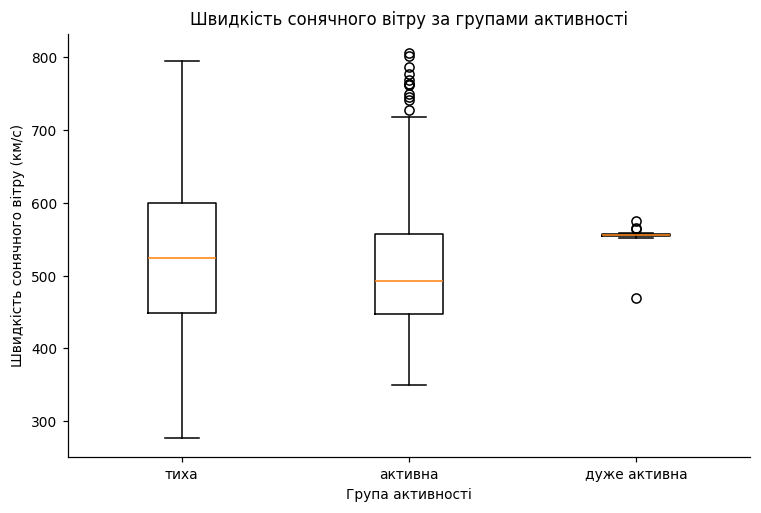

In [ ]:
groups = ['тиха', 'активна', 'дуже активна']
data_by_group = [M.loc[M['група'] == g, 'SPEED'].dropna() for g in groups]

plt.figure(figsize=(8, 5))
plt.boxplot(data_by_group, tick_labels=groups)
plt.xlabel('Група активності')
plt.ylabel('Швидкість сонячного вітру (км/с)')
plt.title('Швидкість сонячного вітру за групами активності')
plt.show()

**Висновок:У групах «тиха» і «активна» швидкість вітру розподілена схоже: медіана «тихої» — близько 525 км/с (ящик 450–600), медіана «активної» — трохи нижча, близько 495 км/с (ящик 450–560), але в «активної» з'явилось багато викидів вище 720 км/с (аж до ~800). У групі «дуже активна» розкид набагато вужчий (ящик стиснутий біля 555–565 км/с) — імовірно через малу кількість спостережень (лише 18 годин), і там же один явний викид нижче 460 км/с. Тобто помітної системної різниці швидкості між групами немає, хоча найактивніші години частіше супроводжуються екстремально високою швидкістю (викиди).**

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Кореляція: 0.2852889299976657


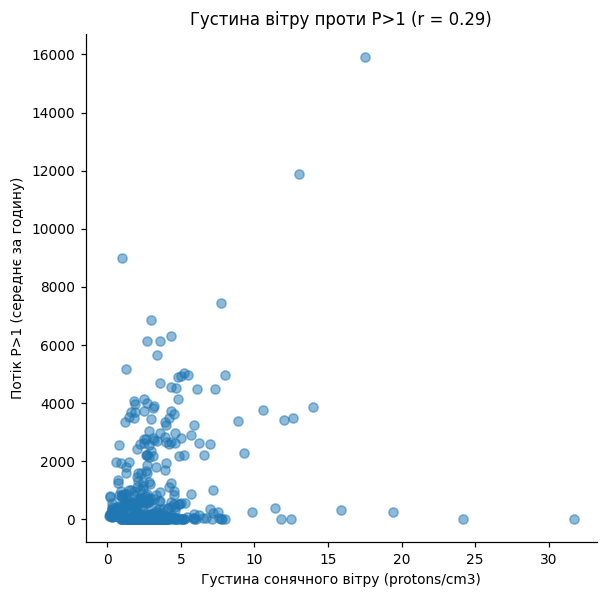

In [ ]:
corr = M[['DENSITY', 'P>1_mean']].corr().iloc[0, 1]
print('Кореляція:', corr)

plt.figure(figsize=(6, 6))
plt.scatter(M['DENSITY'], M['P>1_mean'], alpha=0.5)
plt.xlabel('Густина сонячного вітру (protons/cm3)')
plt.ylabel('Потік P>1 (середнє за годину)')
plt.title(f'Густина вітру проти P>1 (r = {corr:.2f})')
plt.show()

**Висновок:Кореляція між густиною вітру та потоком P>1 становить r = 0.29 — це слабкий позитивний зв'язок: величини пов'язані, але дуже нежорстко, багато точок розкидані незалежно одна від одної. Тобто густина сонячного вітру пояснює лише невелику частину змін у потоці частинок P>1.**

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

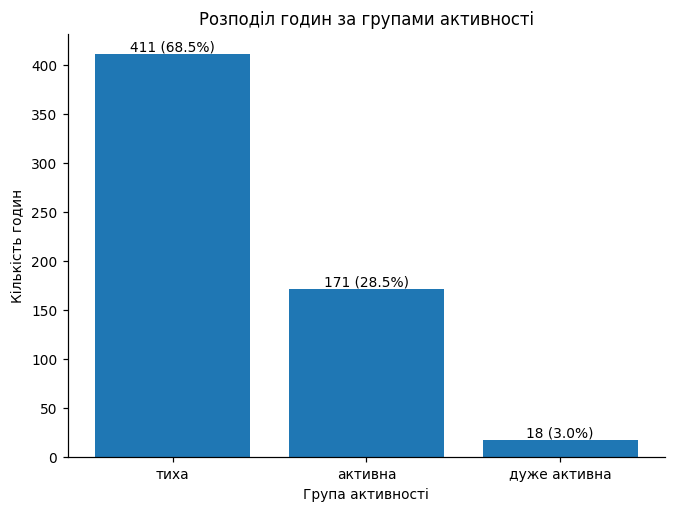

In [ ]:
counts = M['група'].value_counts().reindex(['тиха', 'активна', 'дуже активна'])
percentages = counts / counts.sum() * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(counts.index, counts.values)
plt.xlabel('Група активності')
plt.ylabel('Кількість годин')
plt.title('Розподіл годин за групами активності')

for bar, count, pct in zip(bars, counts.values, percentages.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
              f'{count} ({pct:.1f}%)', ha='center', va='bottom')
plt.show()

**Висновок:З 600 годин, розподілених за групами, 68.5% (411 год) потрапили в групу «тиха», 28.5% (171 год) — «активна», і лише 3.0% (18 год) — «дуже активна». Тобто екстремальна космічна погода в цей період — рідкісне явище, переважна більшість часу космічна погода спокійна.**

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

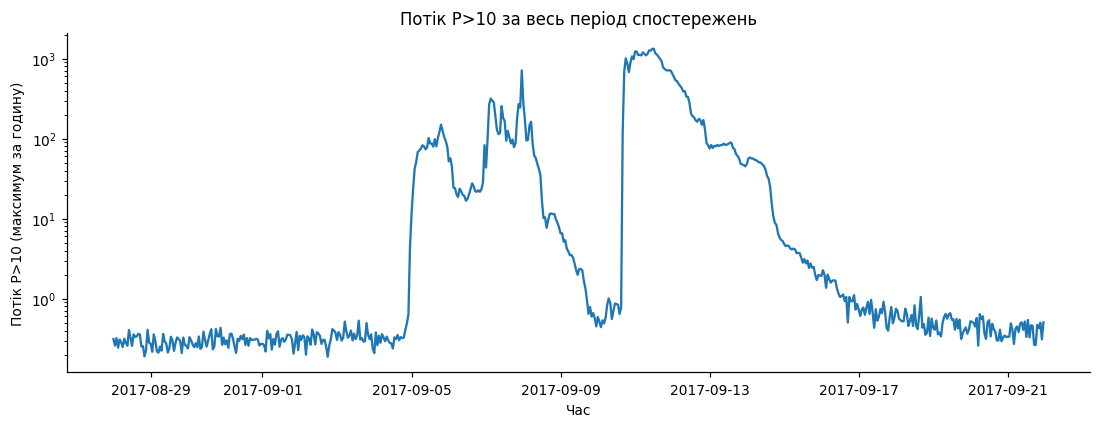

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(M['ts'], M['P>10_max'])
plt.xlabel('Час')
plt.ylabel('Потік P>10 (максимум за годину)')
plt.title('Потік P>10 за весь період спостережень')
plt.yscale('log')
plt.show()

**Висновок:На логарифмічній шкалі добре видно кілька окремих піків активності на тлі відносно стабільного низького фону — на звичайній (лінійній) шкалі ці менші сплески були б непомітні, притиснуті до нуля найбільшим піком.**

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

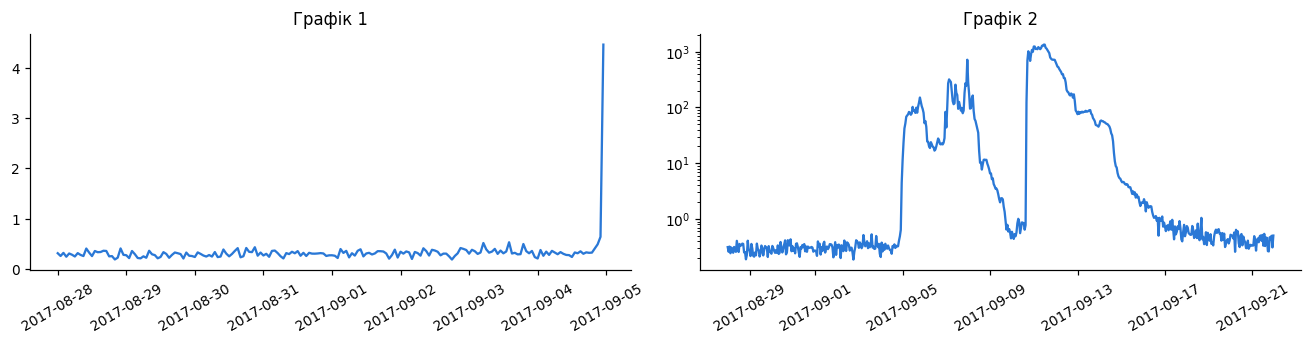

In [38]:
СТОВПЕЦЬ = 'P>10_max'

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: Людина, яка бачила тільки Графік 1 (тиждень, лінійна шкала), зробить висновок, що в цей тиждень практично нічого не відбувалось — крива виглядає майже пласкою біля нуля.
2. Висновок з другого графіка: Людина, яка бачила тільки Графік 2 (весь період, логарифмічна шкала), побачить кілька виразних сплесків активності протягом усього вересня — зовсім інша картина.
3. Дві відмінності між ними: Дві відмінності: (а) різний часовий діапазон (один тиждень vs увесь період спостережень) і (б) різна шкала осі Y (лінійна vs логарифмічна).


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

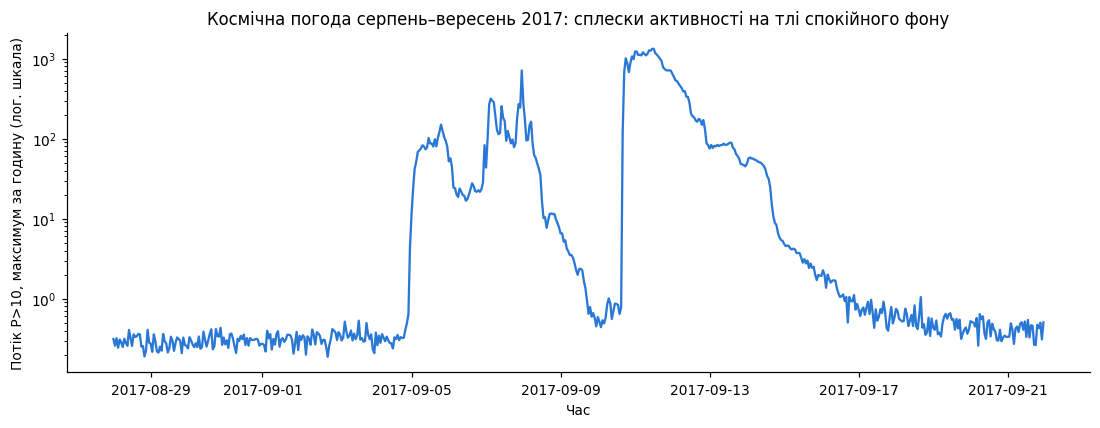

In [ ]:
plt.figure(figsize=(12, 4))
plt.plot(M['ts'], M['P>10_max'], color='#2a78d6')
plt.yscale('log')
plt.xlabel('Час')
plt.ylabel('Потік P>10, максимум за годину (лог. шкала)')
plt.title('Космічна погода серпень–вересень 2017: сплески активності на тлі спокійного фону')
plt.show()

**Відповідь 6.2:** *(чому ви побудували графік саме так)*

Обрала весь період (а не тиждень), щоб не приховати активність поза вузьким вікном, і логарифмічну шкалу, щоб малі й великі сплески були однаково помітні — на лінійній шкалі малі сплески губляться на тлі найбільшого піка, хоча вони теж є значущою космічною погодою.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1: Середнє значення потоку P>30 (18.83) майже у 137 разів більше за медіану (0.138) — видно в Графіку 1 (Етап 5). Це означає, що екстремальні сплески трапляються рідко, але настільки сильні, що сильно спотворюють середнє.**

**Спостереження 2: Густина сонячного вітру й потік P>1 пов'язані слабко (r = 0.29) — видно в Графіку 3 (Етап 5) — тобто густина вітру далеко не єдиний фактор, що визначає потік протонів.**

**Спостереження 3: З 600 годин спостережень лише 18 (3%) потрапили в групу «дуже активна» — видно в Графіку 4 та Завданні 4.4 — екстремальна космічна погода в цей період спостережень була рідкістю.**


### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [ ]:

print(daily)
print('Найбільше середнє:', daily.idxmax().date(), '—', daily.max())
print('Найменше середнє:', daily.idxmin().date(), '—', daily.min())

ts
2017-08-28      0.092297
2017-08-29      0.091266
2017-08-30      0.094493
2017-08-31      0.092460
2017-09-01      0.089734
2017-09-02      0.090684
2017-09-03      0.098962
2017-09-04      0.106562
2017-09-05      0.650576
2017-09-06      1.555274
2017-09-07      4.733031
2017-09-08      2.247031
2017-09-09      0.168946
2017-09-10     82.230478
2017-09-11    292.930556
2017-09-12     64.703125
2017-09-13     13.776701
2017-09-14      5.500592
2017-09-15      0.660118
2017-09-16      0.278938
2017-09-17      0.140767
2017-09-18      0.136539
2017-09-19      0.121408
2017-09-20      0.109478
2017-09-21      0.104707
Freq: D, Name: P>30, dtype: float64
Найбільше середнє: 2017-09-11 — 292.93055555555554
Найменше середнє: 2017-09-01 — 0.08973368055555556


**Відповідь 7.2: Середнє значення потоку P>30 було найбільшим 11 вересня 2017 року (292.93 protons/cm2-s-sr) і найменшим 1 вересня 2017 року (0.090). Тобто пікова доба перевищує найспокійнішу приблизно у 3260 разів. Це узгоджується з Графіком 5/6.2: короткий різкий сплеск активності на тлі майже незмінного низького фону решту періоду.**

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [41]:
ІНСТРУМЕНТИ_ШІ = 'Claude'     

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'синтаксис',
    'етап 3, паспорт даних і дивні значення':     'синтаксис',
    'етап 4, об’єднання таблиць':                 'синтаксис',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'текст, перероблено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = 'Звірила розміри таблиць A/B/C з очікуваними значеннями в assert. Перевірила вручну формулу розбору HHMM та зіставлення року C (17+2000=2017). Перерахувала суму груп 4.4 (411+171+18=600) і кореляцію Графіка 3 (0.29) з фактичним виводом коду. Переписала своїми словами й числами всі текстові висновки під графіками та спостереження, підставивши реальні результати свого варіанту.'

ПІДТВЕРДЖУЮ = True

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [42]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Лящук Соломія
інструменти:                                   Claude
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    синтаксис
етап 3, паспорт даних і дивні значення:        синтаксис
етап 4, об’єднання таблиць:                    синтаксис
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: текст, перероблено
------------------------------------------------------------------------------
перевірено автором:
Звірила розміри таблиць A/B/C з очікуваними значеннями в assert. Перевірила вручну формулу розбору HHMM та зіставлення року C (17+2000=2017). Перерахувала суму груп 4.4 (411+171+18=600) і кореляцію Графіка 3 (0.29) з фактичним виводом коду. Переписала своїми словами й числами всі текстові виснов

---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [43]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 25)


In [44]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
